# 03 · Signatures — Zhang 2019 Follicular Lymphoma

Score the three developmental modules (Gast, pSom, Crest) with `score_genes` against the union control
pool and read their geography off the scoped Body manifold. **Gate 2** asks whether the embryonic module
pattern appears; here Gast and pSom co-vary and both oppose Crest, which peaks at the terminal (late)
end — the **non-branching** case (single collapsed axis, Crest an inverse terminal gradient), which
passes Gate 2 = GO. There is no Gast/pSom two-arm bifurcation, so **Gate 3 = NA** and the branching-only
correlation/modules notebooks are not produced. Deliverable panels show **raw per-cell scores** (smoothing
aids the geography read but the deliverable is raw), plus external colorbars. Deliverable:
`signatures.h5ad`, `{Gast,pSom,Crest}_signature.pdf`, colorbars.

In [1]:
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation', 'pSom':'Somitogenesis', 'Crest':'Neural Crest'}
print('scoped Body manifold:', adata.shape[0], 'cells | scores present:', [m for m in modules if m in adata.obs])
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src, lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')

scoped Body manifold: 5449 cells | scores present: ['Gast', 'pSom', 'Crest']
Gast: 57/81 genes present
pSom: 60/98 genes present
Crest: 81/104 genes present


### Gate 2 — module geography (read on the embedding, smoothed for the read, raw in the deliverable)
Smoothed spatial correlations and the pseudotime gradient show the embryonic relationship on the Body:
Gast and pSom co-vary (r>0), both oppose Crest, and Crest rises to a terminal peak while Gast falls from
the root — a single collapsed developmental axis. No competing pSom/Gast arms exist, so this is the
non-branching case: **Gate 2 = GO, Gate 3 = NA**.

In [4]:
print('smoothed spatial correlations (geography):')
for a, b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.2f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('\ngradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'\nNeural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')
raw_means = {m: round(float(adata.obs[m].mean()),4) for m in ['Gast','pSom','Crest']}
print('global module means (raw, Body):', raw_means)
print('\nGATE 2: shared Gast/pSom gradient + inverse terminal Crest -> GO (non-branching)')
print('GATE 3: no Gast/pSom cross-repression arm (single collapsed axis) -> NA')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = +0.33
  Crest_sm vs Gast_sm: r = -0.83
  Crest_sm vs pSom_sm: r = -0.41

gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.407
  pSom_sm: rho = -0.016
  Crest_sm: rho = +0.430

Neural-crest-high decile mean pseudotime = 0.58 (terminal if ~1)
global module means (raw, Body): {'Gast': 0.012, 'pSom': 0.0051, 'Crest': 0.0098}

GATE 2: shared Gast/pSom gradient + inverse terminal Crest -> GO (non-branching)
GATE 3: no Gast/pSom cross-repression arm (single collapsed axis) -> NA


### Signature geography — three-panel overview (raw scores, house layout)

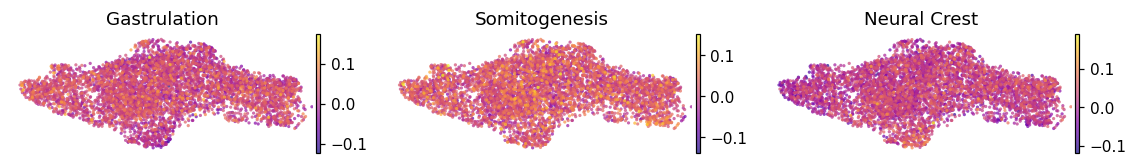

In [5]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, axes = plt.subplots(1, 3, figsize=(10.5,1.6))
for ax,(m,title) in zip(axes, modules.items()):
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=18, colorbar_loc='right',
               frameon=False, show=False, ax=ax, title=title)
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
fig.tight_layout(); plt.show()

### Deliverable signature panels + external colorbars (raw per-cell scores)

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


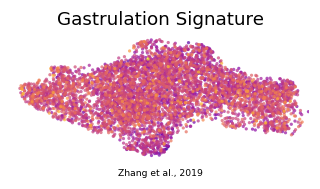

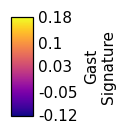

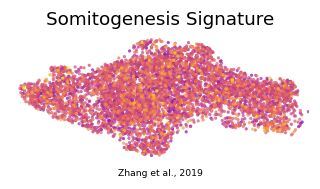

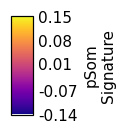

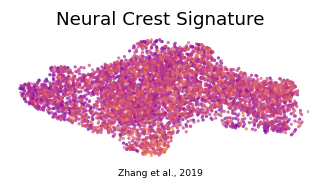

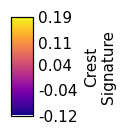

In [6]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=18, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Zhang et al., 2019', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    plt.show()
    print('saved', f'{m}_signature.pdf', '+ colorbar')

### Save signatures

In [7]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (5449, 14715)
